# Занятие 8. Обобщение раздела — демонстрации

Конспект: лекция 8. Своего модуля у занятия нет: все расчёты опираются на модули предыдущих занятий — `trajlib.py` (плоский двухзвенник), `parallel.py` (пятизвенник), `wheeled.py` (колёсные платформы), `aerial.py` (матрица смешивания) — и на цвета `kinlib.py`. Главная мысль ноутбука — **один и тот же аппарат** «ранг, сингулярное разложение, обусловленность, ядро» работает для матриц всех четырёх классов роботов. Поэтому в первой ячейке кода определена одна функция `analyze(M)`, и дальше она вызывается для матрицы Якоби руки, матриц $A$ и $B$ пятизвенника, матрицы $G(\theta)$ тележки, матрицы $H$ меканум-платформы, матрицы смешивания $M$ и составной матрицы мобильного манипулятора.

**Обозначения** (как в конспекте и в `00_Паспорт/Обозначения.md`). Твист схвата $\boldsymbol{\mathcal V}=(\boldsymbol\omega;\mathbf v)$, силовой винт $\mathbf F=(\mathbf m;\mathbf f)$; на плоскости задача схвата — $(\dot x_e,\dot y_e,\dot\varphi_e)$. Сингулярные числа $\sigma_i$, число обусловленности $\kappa(J)=\sigma_{\max}/\sigma_{\min}$ (всегда с аргументом), мера Йошикавы $w=\sigma_1\cdots\sigma_m$. Поза тележки $\boldsymbol\xi=(x,y,\theta)$, скорость в связанных осях $\dot{\boldsymbol\xi}_R=(v_x,v_y,\omega)$, скорости колёс $\dot{\boldsymbol\varphi}=H\dot{\boldsymbol\xi}_R$, $G(\theta)=R_z(\theta)F$. Тяги винтов $\mathbf f$, команды $\mathbf u=(T;\boldsymbol\tau)=M\mathbf f$, $\kappa=k_M/k_F$ — отношение реактивного момента винта к тяге (без аргумента). Составная матрица мобильного манипулятора $J_e=(J_{\mathrm{base}}\ \ J_{\mathrm{arm}})$, переменные $\mathbf z=(v_x,v_y,\omega,\dot q_1,\dot q_2)$. Ветвь двухзвенника $q_2>0$ — «локоть вниз» в осях курса.

**Порядок блоков.** В лекциях твист записывается как $(\boldsymbol\omega;\mathbf v)$, а `kinlib.jacobian`, Robotics Toolbox и большинство библиотек — как $(\mathbf v;\boldsymbol\omega)$. В этом ноутбуке все матрицы плоские и строки подписаны явно.

Демонстрации пронумерованы в порядке показа на занятии; каждая заканчивается числом или рисунком, которые совпадают с конспектом. Ячейка с ползунком (демонстрация 10) работает только при живом запуске; в сохранённом ноутбуке она показывает статичный кадр.

| № | Демонстрация | Конспект | Рисунок | Чем заканчивается |
|---|---|---|---|---|
| 1 | Общий измеритель: двухзвенник у особой точки | § 8.3 | рис. 8.7 | $\sigma_{\min}=0{,}694/0{,}231/0{,}039/0{,}0078$; $\kappa(J)=17$ при $16{,}7^{\circ}$, $30$ при $9{,}5^{\circ}$; пики $2{,}005/4{,}003/8{,}001$ рад/с |
| 2 | Пятизвенник: сила у особенности второго типа | § 8.4 | — | $\boldsymbol\tau=B^{\mathrm T}\boldsymbol\lambda=J^{\mathrm T}\mathbf F$: $0{,}93/21/70/244$ Н·м; вертикальная сила — меньше 1 Н·м |
| 3 | Неголономная тележка: ранг 2 и скобка Ли | § 8.1, § 8.3 | рис. 8.5, 8.6 | $\operatorname{rank}G(\theta)=2$; боковой сдвиг $0{,}339/0{,}089/0{,}022$ м против $\varepsilon^2$ |
| 4 | Меканум-платформа и мультикоптеры | § 8.3, § 8.4 | — | $\sigma(H)=40;\,40;\,15{,}4$; $\sigma(M)=2;\,0{,}247;\,0{,}247;\,0{,}049=2\kappa$; ранг 3 при отказе; ядро гексакоптера 2 |
| 5 | Двойственность скоростей и сил | § 8.4 | рис. 8.8 | полуоси $1{,}618/0{,}618$ и $0{,}618/1{,}618$; мощность $\sum f_iv_i=Tv_z+\tau_x\omega_x+\tau_y\omega_y$ |
| 6 | Калибровка двухзвенника | § 8.5, пример 8.1 | — | 5,32 мм $\to$ 0,064 мм; $\Delta a_1=0{,}02$ мм; контрольная поза 3,1 $\to$ 0,012 мм; ранг 2 у вытянутых поз |
| 7 | Мобильный манипулятор на меканум-платформе | § 8.10, шаги 1–4, 6 | рис. 8.14 | $\sigma(J_e)=1{,}883;\,1{,}022;\,0{,}926$; ядро 2; колёса по 2 рад/с; вытянутая рука — едет платформа |
| 8 | Замкнутый контур CLIK | § 8.10, шаг 5 | рис. 8.10 | $0{,}070/0{,}0091/1{,}5\cdot10^{-4}$ м за 1/2/4 с $=(1-K\Delta t)^k e_0$ |
| 9 | Рука на дифференциальной тележке | § 8.10, шаг 6 | — | $\det=a_1c_1$; при $q_1=90^{\circ}$ теряется движение вдоль первого звена, вбок от курса |
| 10 | Интерактив «сломай и посмотри» | § 8.3, § 8.4 | рис. 8.8 | ползунок $q_2$: эллипсы скоростей и сил, $\kappa(J)$ и пороги 17 и 30 |

In [1]:
import sys, os, warnings
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from kinlib import NAVY, AMB, TEAL, RED, GREY, ICE, GREEN
import trajlib, parallel, wheeled, aerial
np.set_printoptions(precision=4, suppress=True)
warnings.filterwarnings('ignore')
%matplotlib inline
deg, rad = np.degrees, np.radians
try:
    from ipywidgets import interact, FloatSlider
except ImportError:
    interact = None; print('ipywidgets не установлен: интерактивная ячейка покажет только статичную картинку')


def analyze(M, name='', tol=1e-10, show=True):
    """Общий измеритель для любой матрицы скоростей или сил: SVD M = U Σ Vᵀ.
    Возвращает словарь: сингулярные числа, σ_min, число обусловленности κ = σ_max/σ_min (inf при потере ранга),
    мера Йошикавы w = σ₁σ₂⋯σ_m (для «широкой» или квадратной матрицы), ранг, базис ядра (столбцы),
    теряемое направление u_min (последний столбец U) и направление в пространстве приводов v_min."""
    M = np.atleast_2d(np.asarray(M, float)); m, n = M.shape
    U, S, Vt = np.linalg.svd(M)
    r = int(np.sum(S > tol * max(1.0, S[0])))
    smin = S[min(m, n) - 1]
    res = dict(sv=S, smin=smin, kappa=(S[0] / smin if smin > tol else np.inf),
               w=(np.prod(S) if m <= n else np.nan), rank=r, kernel=Vt[r:].T, u_min=U[:, min(m, n) - 1],
               v_min=Vt[min(m, n) - 1])
    if show:
        k = res['kappa']
        print('%-34s %dx%d  ранг %d  σ = %s  κ = %s  ядро: %d' % (name, m, n, r, np.array2string(S, precision=4),
              ('%.3g' % k) if np.isfinite(k) else 'inf', res['kernel'].shape[1]))
    return res

## 1. Общий измеритель: двухзвенник у особой точки (§ 8.3)

Плоский двухзвенник с единичными звеньями, $\det J_v=s_2$. Разгибаем локоть от $110^{\circ}$ к вытянутой руке ($q_1=-15^{\circ}$; сингулярные числа от $q_1$ не зависят). Ожидаем: $\sigma_{\min}=0{,}694$; $0{,}231$; $0{,}039$; $0{,}0078$ при $q_2=110^{\circ}$; $30^{\circ}$; $5^{\circ}$; $1^{\circ}$, а $\kappa(J)=1{,}95$; $9{,}4$; $57$; $286$. Модуль MoveIt Servo по умолчанию замедляет робота при $\kappa(J)>17$ и останавливает при $30$; у этого двухзвенника пороги достигаются при $q_2\approx16{,}7^{\circ}$ и $9{,}5^{\circ}$.

Вторая часть — проход схвата по прямой $y=y_0$ мимо особой точки в основании (раздел 4.9) со скоростью $0{,}4$ м/с, скорости сочленений — чистым обращением $\dot{\mathbf q}=J^{-1}\mathbf v$ **без обратной связи**, ветвь $q_2>0$. Пик $\lvert\dot q_1\rvert$ должен быть почти точно $v/y_0$: $2{,}005$; $4{,}003$; $8{,}001$ рад/с при $y_0=0{,}2$; $0{,}1$; $0{,}05$ м. (В демонстрации 12 ноутбука 4 тот же проход идёт с обратной связью $K=10$ с$^{-1}$, и пик при $y_0=0{,}05$ м чуть выше — $8{,}1$ рад/с.)

двухзвенник, q2 = 110°             2x2  ранг 2  σ = [1.3545 0.6938]  κ = 1.95  ядро: 0
двухзвенник, q2 =  90°             2x2  ранг 2  σ = [1.618 0.618]  κ = 2.62  ядро: 0
двухзвенник, q2 =  60°             2x2  ранг 2  σ = [1.9501 0.4441]  κ = 4.39  ядро: 0
двухзвенник, q2 =  30°             2x2  ранг 2  σ = [2.163  0.2312]  κ = 9.36  ядро: 0
двухзвенник, q2 =  10°             2x2  ранг 2  σ = [2.2279 0.0779]  κ = 28.6  ядро: 0
двухзвенник, q2 =   5°             2x2  ранг 2  σ = [2.234 0.039]  κ = 57.3  ядро: 0
двухзвенник, q2 =   1°             2x2  ранг 2  σ = [2.236  0.0078]  κ = 286  ядро: 0

κ(J) = 17 при q2 = 16.75°, κ(J) = 30 при q2 = 9.53° (пороги MoveIt Servo по умолчанию)
теряемое направление при q2 = 5°: u_min = [-0.978  0.208] — вдоль руки (рука почти вытянута под углом -12.5°)


прямая y0 = 0.20 м: пик |q̇1| = 2.005 рад/с при x = -0.0100 м (v/y0 = 2.0); σ_min в точке x = 0: 0.1990


прямая y0 = 0.10 м: пик |q̇1| = 4.003 рад/с при x = -0.0025 м (v/y0 = 4.0); σ_min в точке x = 0: 0.0999


прямая y0 = 0.05 м: пик |q̇1| = 8.001 рад/с при x = -0.0006 м (v/y0 = 8.0); σ_min в точке x = 0: 0.0500


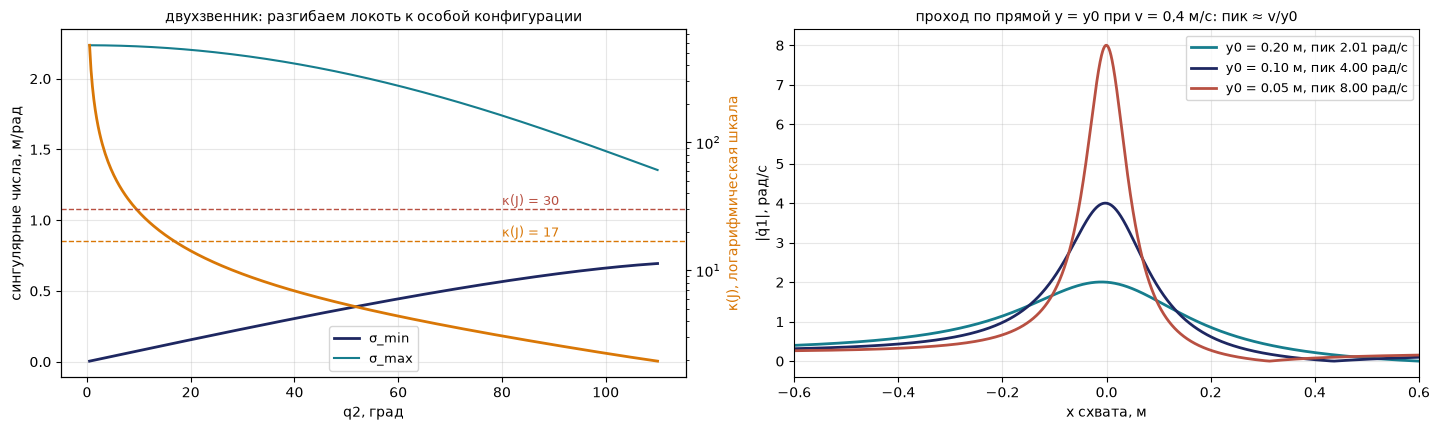

In [2]:
J2 = trajlib.J2
for q2d in (110, 90, 60, 30, 10, 5, 1):
    analyze(J2(rad([-15.0, q2d])), 'двухзвенник, q2 = %3d°' % q2d)

from scipy.optimize import brentq
kap = lambda q2: analyze(J2([0.0, q2]), show=False)['kappa']
q17, q30 = brentq(lambda x: kap(x) - 17, 1e-4, 1.5), brentq(lambda x: kap(x) - 30, 1e-4, 1.5)
print('\nκ(J) = 17 при q2 = %.2f°, κ(J) = 30 при q2 = %.2f° (пороги MoveIt Servo по умолчанию)' % (deg(q17), deg(q30)))
r1 = analyze(J2(rad([-15.0, 5.0])), show=False)
print('теряемое направление при q2 = 5°: u_min =', r1['u_min'].round(3), '— вдоль руки (рука почти вытянута под углом %.1f°)' % deg(np.arctan2(*trajlib.fk2(rad([-15.0, 5.0]))[::-1])))

v = 0.4; peaks = {}
for y0 in (0.2, 0.1, 0.05):
    xs = np.concatenate([np.linspace(-1.5, -0.01, 3000), np.linspace(-0.01, 0.01, 20001), np.linspace(0.01, 1.5, 3000)])
    qd1 = np.array([np.linalg.solve(J2(trajlib.ik2([x, y0], elbow=1)), [v, 0.0])[0] for x in xs])
    i = np.argmax(np.abs(qd1)); peaks[y0] = (xs, qd1)
    s = analyze(J2(trajlib.ik2([0.0, y0], elbow=1)), show=False)['smin']
    print('прямая y0 = %.2f м: пик |q̇1| = %.3f рад/с при x = %.4f м (v/y0 = %.1f); σ_min в точке x = 0: %.4f' % (y0, abs(qd1[i]), xs[i], v / y0, s))

fig, axs = plt.subplots(1, 2, figsize=(14.5, 4.4))
qq = np.linspace(rad(0.5), rad(110), 400)
ss = np.array([analyze(J2([0.0, q]), show=False)['sv'] for q in qq])
ax = axs[0]; ax.plot(deg(qq), ss[:, 1], color=NAVY, lw=2, label='σ_min'); ax.plot(deg(qq), ss[:, 0], color=TEAL, lw=1.5, label='σ_max')
ax2 = ax.twinx(); ax2.semilogy(deg(qq), ss[:, 0] / ss[:, 1], color=AMB, lw=2, label='κ(J)')
for k_, c_ in ((17, AMB), (30, RED)):
    ax2.axhline(k_, color=c_, ls='--', lw=1); ax2.text(80, k_ * 1.08, 'κ(J) = %d' % k_, color=c_, fontsize=9)
ax2.set_ylabel('κ(J), логарифмическая шкала', color=AMB)
ax.set_xlabel('q2, град'); ax.set_ylabel('сингулярные числа, м/рад'); ax.grid(alpha=.3); ax.legend(loc='lower center', fontsize=9)
ax.set_title('двухзвенник: разгибаем локоть к особой конфигурации', fontsize=10)
ax = axs[1]
for (y0, (xs, qd1)), c_ in zip(sorted(peaks.items(), reverse=True), (TEAL, NAVY, RED)):
    ax.plot(xs, np.abs(qd1), color=c_, lw=2, label='y0 = %.2f м, пик %.2f рад/с' % (y0, np.abs(qd1).max()))
ax.set_xlim(-0.6, 0.6); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('x схвата, м'); ax.set_ylabel('|q̇1|, рад/с')
ax.set_title('проход по прямой y = y0 при v = 0,4 м/с: пик ≈ v/y0', fontsize=10)
plt.tight_layout(); plt.show()

## 2. Пятизвенник: сила у особенности второго типа (§ 8.4)

Пятизвенник раздела 5.3 ($d=0{,}3$ м, $l_1=0{,}3$ м, $l_2=0{,}45$ м, сборка «+»): уравнение скоростей $A\dot{\mathbf x}=B\dot{\mathbf q}$, строки $A$ — векторы ведомых звеньев, $B$ диагональна. Двойственность через множители связей: $A^{\mathrm T}\boldsymbol\lambda=\mathbf F$, $\boldsymbol\tau=B^{\mathrm T}\boldsymbol\lambda$, и при $\det A\ne0$ это то же, что $\boldsymbol\tau=J^{\mathrm T}\mathbf F$. Идём по пути $\mathbf q=(60^{\circ}+\Delta;\ 120^{\circ}-\Delta)$ к особенности второго типа ($\Delta\to0$: точки $B_1$, $P$, $B_2$ на одной прямой). Ожидаем: горизонтальная сила 10 Н требует от каждого привода $0{,}93$; $21$; $70$; $244$ Н·м при $\Delta=15^{\circ}$; $3^{\circ}$; $1^{\circ}$; $0{,}3^{\circ}$, а вертикальная — меньше 1 Н·м. Функция `analyze` показывает, что вырождается именно $A$, а $B$ остаётся невырожденной.

Δ = 15.0°: P = (-0.000; 0.734) м, τ(горизонтальная 10 Н) = [0.93 0.93] Н·м, проверка JᵀF = [0.93 0.93], τ(вертикальная) = [ 0.15 -0.15] Н·м
   A/l2 (безразмерная)             2x2  ранг 2  σ = [1.3958 0.2274]  κ = 6.14  ядро: 0
   B                               2x2  ранг 2  σ = [0.0135 0.0135]  κ = 1  ядро: 0
Δ =  9.0°: P = (0.000; 0.728) м, τ(горизонтальная 10 Н) = [4.27 4.27] Н·м, проверка JᵀF = [4.27 4.27], τ(вертикальная) = [ 0.4 -0.4] Н·м
Δ =  3.0°: P = (0.000; 0.717) м, τ(горизонтальная 10 Н) = [20.85 20.85] Н·м, проверка JᵀF = [20.85 20.85], τ(вертикальная) = [ 0.64 -0.64] Н·м
Δ =  1.0°: P = (0.000; 0.712) м, τ(горизонтальная 10 Н) = [70.49 70.49] Н·м, проверка JᵀF = [70.49 70.49], τ(вертикальная) = [ 0.71 -0.71] Н·м
Δ =  0.3°: P = (-0.000; 0.711) м, τ(горизонтальная 10 Н) = [244.17 244.17] Н·м, проверка JᵀF = [244.17 244.17], τ(вертикальная) = [ 0.74 -0.74] Н·м
   A/l2 (безразмерная)             2x2  ранг 2  σ = [1.4142 0.0043]  κ = 330  ядро: 0
   B                            

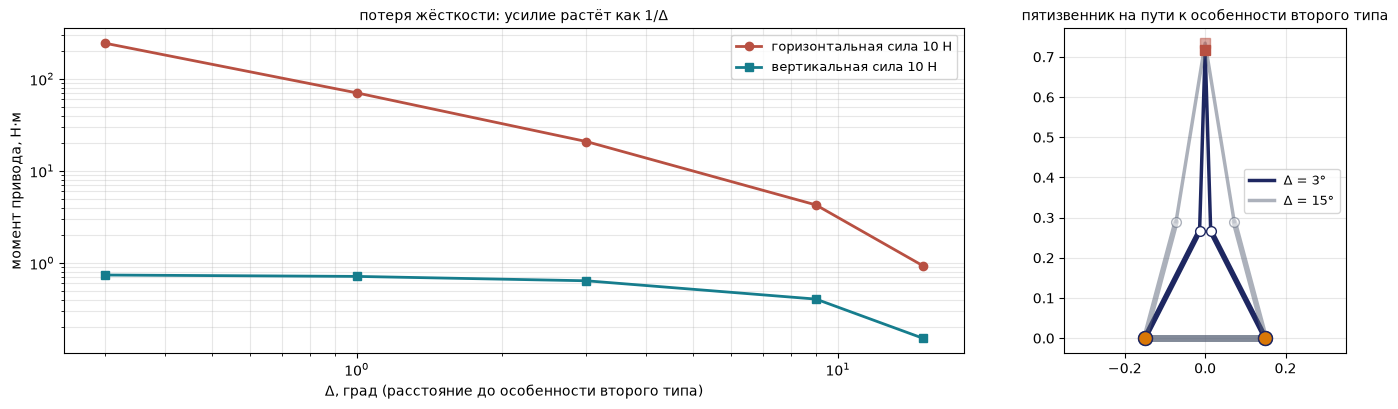

In [3]:
F_h, F_v = np.array([10.0, 0.0]), np.array([0.0, 10.0])
rows = []
for Dg in (15, 9, 3, 1, 0.3):
    q = rad([60 + Dg, 120 - Dg]); P, B1, B2 = parallel.fivebar_fk(q[0], q[1], mode=+1)
    A, B, J = parallel.fivebar_jac(P, q)
    lam = np.linalg.solve(A.T, F_h); tau = B.T.dot(lam)
    rows.append((Dg, abs(tau[0]), np.abs(J.T.dot(F_v)).max()))
    print('Δ = %4.1f°: P = (%.3f; %.3f) м, τ(горизонтальная 10 Н) = %s Н·м, проверка JᵀF = %s, τ(вертикальная) = %s Н·м'
          % (Dg, P[0], P[1], tau.round(2), J.T.dot(F_h).round(2), J.T.dot(F_v).round(2)))
    if Dg in (15, 0.3):
        analyze(A / parallel.FB_L2, '   A/l2 (безразмерная)'); analyze(B, '   B')

fig, ax = plt.subplots(1, 2, figsize=(14.5, 4.2), gridspec_kw=dict(width_ratios=[2.0, 1.0]))
D_ = np.array([r[0] for r in rows])
ax[0].loglog(D_, [r[1] for r in rows], 'o-', color=RED, lw=2, label='горизонтальная сила 10 Н')
ax[0].loglog(D_, [r[2] for r in rows], 's-', color=TEAL, lw=2, label='вертикальная сила 10 Н')
ax[0].set_xlabel('Δ, град (расстояние до особенности второго типа)'); ax[0].set_ylabel('момент привода, Н·м'); ax[0].grid(alpha=.3, which='both'); ax[0].legend(fontsize=9)
ax[0].set_title('потеря жёсткости: усилие растёт как 1/Δ', fontsize=10)
q = rad([60 + 3, 120 - 3]); parallel.draw_fivebar(ax[1], q[0], q[1], mode=+1, color=NAVY, label='Δ = 3°')
q = rad([60 + 15, 120 - 15]); parallel.draw_fivebar(ax[1], q[0], q[1], mode=+1, color=GREY, alpha=.5, label='Δ = 15°')
ax[1].set_aspect('equal'); ax[1].set_xlim(-0.35, 0.35); ax[1].grid(alpha=.3); ax[1].legend(fontsize=9, loc='center right'); ax[1].set_title('пятизвенник на пути к особенности второго типа', fontsize=10)
plt.tight_layout(); plt.show()

## 3. Неголономная тележка: ранг 2 и скобка Ли (§ 8.1, § 8.3)

Дифференциальная тележка ($r=0{,}05$ м, $b=0{,}3$ м): $\dot{\boldsymbol\xi}=G(\theta)\dot{\boldsymbol\varphi}$, $G(\theta)=R_z(\theta)F$ размера $3\times2$. Ранг равен двум при **любом** курсе — это свойство схемы, а не особая точка. Скобка Ли полей «ехать» $\mathbf g_1=(\cos\theta,\sin\theta,0)$ и «поворачиваться» $\mathbf g_2=(0,0,1)$ равна $(\sin\theta,-\cos\theta,0)$ — запрещённое боковое направление, — и вместе с $\mathbf g_1$, $\mathbf g_2$ даёт ранг 3. Манёвр «вперёд $\varepsilon$ — поворот $\varepsilon$ — назад $\varepsilon$ — поворот обратно» возвращает углы колёс к исходным значениям, а корпус сдвигает вбок на величину порядка $\varepsilon^2$: $0{,}339$; $0{,}089$; $0{,}022$ м при $\varepsilon=0{,}6$; $0{,}3$; $0{,}15$.

G(θ), θ = 0.0 рад                  3x2  ранг 2  σ = [0.2357 0.0354]  κ = 6.67  ядро: 0
G(θ), θ = 0.7 рад                  3x2  ранг 2  σ = [0.2357 0.0354]  κ = 6.67  ядро: 0
G(θ), θ = 2.0 рад                  3x2  ранг 2  σ = [0.2357 0.0354]  κ = 6.67  ядро: 0

скобка Ли [g1, g2] при θ = 0,7: [ 0.6442 -0.7648  0.    ]  ожидаем (sin θ, −cos θ, 0) = [ 0.6442 -0.7648  0.    ]
ранг (g1, g2, [g1, g2]) = 3
ε = 0.60: конечная поза (0.1048; -0.3388; 2.8e-17), боковой сдвиг 0.339 м, ε² = 0.3600, сумма поворотов колёс [-0.  0.] рад
ε = 0.30: конечная поза (0.0134; -0.0887; 1.4e-17), боковой сдвиг 0.089 м, ε² = 0.0900, сумма поворотов колёс [-0.  0.] рад
ε = 0.15: конечная поза (0.0017; -0.0224; 6.9e-18), боковой сдвиг 0.022 м, ε² = 0.0225, сумма поворотов колёс [-0.  0.] рад


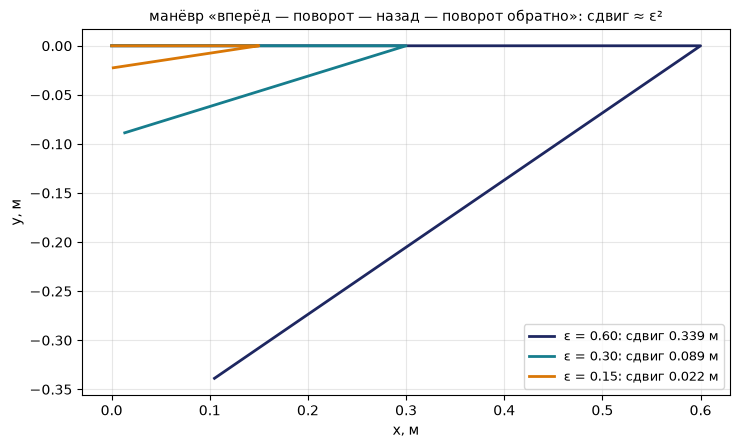

In [4]:
for th in (0.0, 0.7, 2.0):
    analyze(wheeled.dd_G(th), 'G(θ), θ = %.1f рад' % th)
q0 = np.array([0.3, -0.2, 0.7])
br = wheeled.lie_bracket_num(wheeled.g1, wheeled.g2, q0)
print('\nскобка Ли [g1, g2] при θ = 0,7:', br.round(4), ' ожидаем (sin θ, −cos θ, 0) =', np.array([np.sin(0.7), -np.cos(0.7), 0]).round(4))
print('ранг (g1, g2, [g1, g2]) =', np.linalg.matrix_rank(np.c_[wheeled.g1(q0), wheeled.g2(q0), br]))

r, b = wheeled.DD_R, wheeled.DD_B
fig, ax = plt.subplots(figsize=(7.5, 4.6))
for eps, c_ in ((0.6, NAVY), (0.3, TEAL), (0.15, AMB)):
    path, marks = wheeled.lie_maneuver(eps)
    # углы колёс: правое (v + ω b/2)/r, левое (v − ω b/2)/r, проинтегрированные по четырём шагам
    dphi = sum(np.array([(v_ + w_ * b / 2) / r, (v_ - w_ * b / 2) / r]) * eps for v_, w_ in ((1, 0), (0, 1), (-1, 0), (0, -1)))
    end = marks[-1]
    print('ε = %.2f: конечная поза (%.4f; %.4f; %.1e), боковой сдвиг %.3f м, ε² = %.4f, сумма поворотов колёс %s рад'
          % (eps, end[0], end[1], end[2], abs(end[1]), eps ** 2, dphi.round(12)))
    ax.plot(path[:, 0], path[:, 1], color=c_, lw=2, label='ε = %.2f: сдвиг %.3f м' % (eps, abs(end[1])))
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(fontsize=9); ax.set_xlabel('x, м'); ax.set_ylabel('y, м')
ax.set_title('манёвр «вперёд — поворот — назад — поворот обратно»: сдвиг ≈ ε²', fontsize=10)
plt.tight_layout(); plt.show()

## 4. Меканум-платформа и мультикоптеры (§ 8.3, § 8.4)

Меканум-платформа примера 6.6 ($r=0{,}05$ м, $l_x=0{,}235$ м, $l_y=0{,}15$ м): у матрицы $H$ столбцы ортогональны, сингулярные числа постоянны — $40$, $40$ (поступательные компоненты, рад/с на м/с) и $15{,}4$ (вращение) — и вырождения нет ни в одной позе. Ядро $H^{\mathrm T}$ — вектор $(1,1,-1,-1)$: такие моменты колёс не создают на корпусе ни силы, ни момента.

Квадрокоптер Hummingbird в схеме «X»: $\sigma(M)=2$; $0{,}247$; $0{,}247$; $0{,}049$. Наименьшее отвечает рысканию, и оно равно $2\kappa$, где $\kappa=k_M/k_F\approx0{,}0245$ м — плечо реактивного момента, в пять раз меньше плеча крена $d=0{,}124$ м. Отказ мотора вычёркивает столбец, и ранг падает до трёх; у гексакоптера ранг сохраняется, а двумерное ядро $M$ — аналог самодвижения избыточной руки. Сравнивать между собой сингулярные числа с разными единицами нельзя: строки $M$ — ньютоны и ньютон-метры.

In [5]:
H = wheeled.mec_H(); rH = analyze(H, 'меканум, H (4×3)')
print('Hᵀ (1, 1, −1, −1) =', H.T.dot([1, 1, -1, -1]), ';  столбцы H ортогональны: HᵀH =\n', H.T.dot(H).round(2))
M = aerial.mixer_x(); rM = analyze(M, 'квадрокоптер «X», M (4×4)')
print('наименьшее σ(M) = %.4f = 2κ = %.4f м;  плечо крена d = %.4f м, отношение %.1f' % (rM['smin'], 2 * aerial.KAPPA, aerial.D_Q, aerial.D_Q / aerial.KAPPA))
print('направление наименьшего σ в пространстве команд u = (T; τx, τy, τz):', rM['u_min'].round(3), '— рыскание')
for i in range(4):
    analyze(np.delete(M, i, axis=1), 'отказ мотора %d: M без столбца' % (i + 1))
xy, eps = aerial.hexa_geometry(); Mh = aerial.mixer_general(xy, eps); rh = analyze(Mh, 'гексакоптер PNPNPN, M (4×6)')
print('базис ядра M гексакоптера (перераспределения тяг без изменения T и τ):\n', rh['kernel'].round(3))
print('проверка: M · ядро =', np.abs(Mh.dot(rh['kernel'])).max().round(15))

меканум, H (4×3)                   4x3  ранг 3  σ = [40.  40.  15.4]  κ = 2.6  ядро: 0
Hᵀ (1, 1, −1, −1) = [0. 0. 0.] ;  столбцы H ортогональны: HᵀH =
 [[1600.      0.      0.  ]
 [   0.   1600.     -0.  ]
 [   0.     -0.    237.16]]
квадрокоптер «X», M (4×4)          4x4  ранг 4  σ = [2.     0.2475 0.2475 0.0491]  κ = 40.7  ядро: 0
наименьшее σ(M) = 0.0491 = 2κ = 0.0491 м;  плечо крена d = 0.1237 м, отношение 5.0
направление наименьшего σ в пространстве команд u = (T; τx, τy, τz): [ 0.  0. -0.  1.] — рыскание
отказ мотора 1: M без столбца      4x3  ранг 3  σ = [1.7351 0.2475 0.1482]  κ = 11.7  ядро: 0
отказ мотора 2: M без столбца      4x3  ранг 3  σ = [1.7351 0.2475 0.1482]  κ = 11.7  ядро: 0
отказ мотора 3: M без столбца      4x3  ранг 3  σ = [1.7351 0.2475 0.1482]  κ = 11.7  ядро: 0
отказ мотора 4: M без столбца      4x3  ранг 3  σ = [1.7351 0.2475 0.1482]  κ = 11.7  ядро: 0
гексакоптер PNPNPN, M (4×6)        4x6  ранг 4  σ = [2.4495 0.3031 0.3031 0.0601]  κ = 40.7  ядро: 2
базис я

## 5. Двойственность скоростей и сил (§ 8.4)

Мощность приводов равна мощности, передаваемой схватом: $\boldsymbol\tau^{\mathrm T}\dot{\mathbf q}=\mathbf F^{\mathrm T}J\dot{\mathbf q}$ при любых $\dot{\mathbf q}$, откуда $\boldsymbol\tau=J^{\mathrm T}\mathbf F$. Эллипс скоростей — образ единичного круга $\lVert\dot{\mathbf q}\rVert\le1$ с полуосями $\sigma_i\hat{\mathbf u}_i$; эллипс сил — множество сил, которые создаются моментами $\lVert\boldsymbol\tau\rVert\le1$, с теми же осями и полуосями $1/\sigma_i$. У двухзвенника с единичными звеньями при $q_2=90^{\circ}$: $1{,}618$ и $0{,}618$ против $0{,}618$ и $1{,}618$.

Для квадрокоптера та же проверка мощностью: точка крепления винта $i$ движется вдоль его оси со скоростью $v_i=v_z+\omega_xy_i-\omega_yx_i$, то есть $\mathbf v_{\mathrm{rot}}=J_r(v_z,\omega_x,\omega_y)^{\mathrm T}$, и $\sum_if_iv_i=Tv_z+\tau_x\omega_x+\tau_y\omega_y$ при любых тягах. Значит, первые три строки $M$ равны $J_r^{\mathrm T}$: матрица смешивания — силовой мост, аналог $J^{\mathrm T}$, а не $J$.

двухзвенник, q2 = 90°              2x2  ранг 2  σ = [1.618 0.618]  κ = 2.62  ядро: 0
полуоси эллипса скоростей: [1.618 0.618] ;  эллипса сил: [1.618 0.618]
проверка мощности τᵀq̇ − Fᵀ(Jq̇) = 0.0

первые три строки M равны J_rᵀ: True
мощность тяг Σ f_i v_i = -4.660126;  T v_z + τx ωx + τy ωy = -4.660126


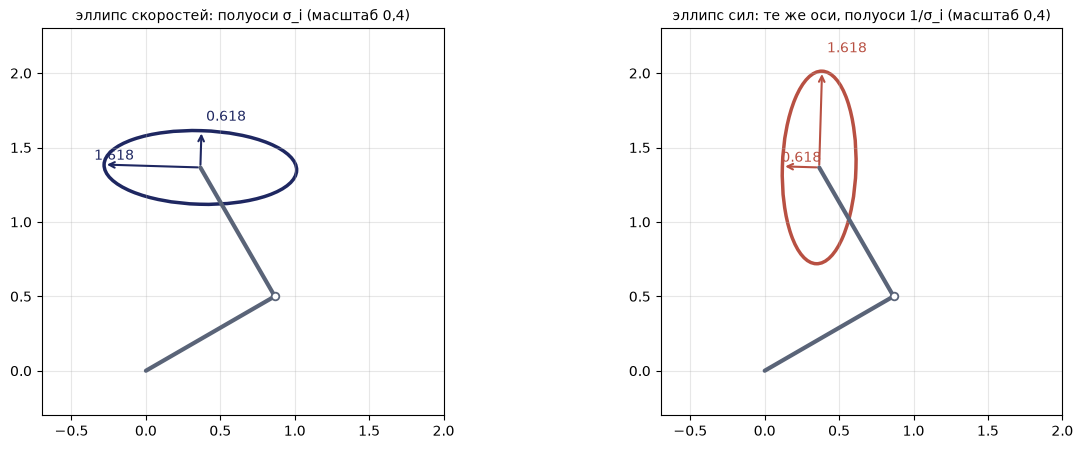

In [6]:
q = rad([30.0, 90.0]); J = J2(q); r_ = analyze(J, 'двухзвенник, q2 = 90°')
Jinv_T = np.linalg.inv(J).T
print('полуоси эллипса скоростей:', r_['sv'].round(3), ';  эллипса сил:', np.sort(1 / r_['sv'])[::-1].round(3))
rng = np.random.default_rng(0); qd = rng.normal(size=2); F = rng.normal(size=2)
print('проверка мощности τᵀq̇ − Fᵀ(Jq̇) =', (J.T.dot(F)).dot(qd) - F.dot(J.dot(qd)))

xy = np.array([(aerial.D_Q, -aerial.D_Q), (-aerial.D_Q, aerial.D_Q), (aerial.D_Q, aerial.D_Q), (-aerial.D_Q, -aerial.D_Q)])
Jr = np.array([[1.0, y, -x] for x, y in xy])
print('\nпервые три строки M равны J_rᵀ:', np.allclose(M[:3], Jr.T))
f = rng.uniform(0.5, 2.0, 4); V = rng.normal(size=3); u = M.dot(f)
print('мощность тяг Σ f_i v_i = %.6f;  T v_z + τx ωx + τy ωy = %.6f' % (f.dot(Jr.dot(V)), u[:3].dot(V)))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))
p = trajlib.fk2(q); U = np.linalg.svd(J)[0]; ang = deg(np.arctan2(U[1, 0], U[0, 0]))
for ax, sc, col, ttl in ((axs[0], r_['sv'], NAVY, 'эллипс скоростей: полуоси σ_i'), (axs[1], 1 / r_['sv'], RED, 'эллипс сил: те же оси, полуоси 1/σ_i')):
    trajlib.draw_arm(ax, q, color=GREY)
    ax.add_patch(Ellipse(p, 2 * sc[0] * 0.4, 2 * sc[1] * 0.4, angle=ang, fc='none', ec=col, lw=2.5))
    for k_ in range(2):
        d_ = U[:, k_] * sc[k_] * 0.4; ax.annotate('', p + d_, p, arrowprops=dict(arrowstyle='->', color=col, lw=1.5))
        ax.text(*(p + d_ * 1.15 + np.array([0.03, 0.03])), '%.3f' % sc[k_], color=col, fontsize=10)
    ax.set_aspect('equal'); ax.set_xlim(-0.7, 2.0); ax.set_ylim(-0.3, 2.3); ax.grid(alpha=.3); ax.set_title(ttl + ' (масштаб 0,4)', fontsize=10)
plt.tight_layout(); plt.show()

## 6. Калибровка двухзвенника (§ 8.5, пример 8.1)

**Пример 8.1.** Номинальная модель двухзвенника $a_1=1$ м, $a_2=0{,}7$ м без поправок нулей; настоящий робот — $a_1=1{,}002$ м, $a_2=0{,}698$ м и смещения нулей $0{,}2^{\circ}$ и $-0{,}3^{\circ}$. Положение схвата измерено внешним прибором с шумом $0{,}05$ мм в десяти конфигурациях. Вектор параметров $\boldsymbol\beta=(a_1,a_2,\Delta q_1,\Delta q_2)$, «якобиан по параметрам» $J_\beta=\partial\mathbf p/\partial\boldsymbol\beta$, шаг Гаусса — Ньютона $\Delta\boldsymbol\beta=J_\beta^{+}\,\Delta\mathbf p$ по всем позам сразу.

Ожидаем: до калибровки ошибка до $5{,}32$ мм (в среднем $2{,}98$ мм); после двух итераций остаток $0{,}064$ мм — на уровне шума; длины восстановлены с точностью до десятков микрометров ($a_1$ — около $0{,}02$ мм, $a_2$ — около $0{,}001$ мм), нули — до тысячных долей градуса; в контрольной позе ошибка падает с $3{,}1$ до $0{,}012$ мм. Если мерить только вытянутую руку, ранг $J_\beta$ равен двум из четырёх, и длины звеньев по отдельности не определяются.

In [7]:
def fk_b(q, b):
    a1, a2, d1, d2 = b; t1 = q[0] + d1; t2 = q[1] + d2
    return np.array([a1 * np.cos(t1) + a2 * np.cos(t1 + t2), a1 * np.sin(t1) + a2 * np.sin(t1 + t2)])

def J_beta(q, b):
    a1, a2, d1, d2 = b; t1 = q[0] + d1; t12 = t1 + q[1] + d2
    return np.array([[np.cos(t1), np.cos(t12), -a1 * np.sin(t1) - a2 * np.sin(t12), -a2 * np.sin(t12)],
                     [np.sin(t1), np.sin(t12), a1 * np.cos(t1) + a2 * np.cos(t12), a2 * np.cos(t12)]])

nom = np.array([1.0, 0.7, 0.0, 0.0]); true = np.array([1.002, 0.698, rad(0.2), rad(-0.3)])
Q = rad(np.array([[-60, 30], [-30, 90], [0, 45], [20, 120], [45, 60], [70, 20], [90, 100], [120, 70], [150, 30], [-90, 140]]))
rng = np.random.default_rng(1)
meas = np.array([fk_b(q, true) for q in Q]) + rng.normal(0, 0.05e-3, (len(Q), 2))
err = lambda b: np.linalg.norm(meas - np.array([fk_b(q, b) for q in Q]), axis=1) * 1e3
e0 = err(nom); print('по номинальной модели: ошибка до %.2f мм, в среднем %.2f мм' % (e0.max(), e0.mean()))
analyze(np.vstack([J_beta(q, nom) for q in Q]), 'J_β, десять поз (20×4)')
b = nom.copy()
for it in range(2):
    r = (meas - np.array([fk_b(q, b) for q in Q])).ravel()
    b = b + np.linalg.lstsq(np.vstack([J_beta(q, b) for q in Q]), r, rcond=None)[0]
    e1 = err(b); print('итерация %d: остаток до %.3f мм, в среднем %.3f мм' % (it + 1, e1.max(), e1.mean()))
d = b - true
print('ошибки параметров: Δa1 = %.1f мкм, Δa2 = %.1f мкм, Δq1 = %.5f°, Δq2 = %.5f°' % (d[0] * 1e6, d[1] * 1e6, deg(d[2]), deg(d[3])))
qt = rad([10.0, 80.0])
print('контрольная поза (10°; 80°): %.2f мм по номинальной модели, %.3f мм после калибровки'
      % (np.linalg.norm(fk_b(qt, true) - fk_b(qt, nom)) * 1e3, np.linalg.norm(fk_b(qt, true) - fk_b(qt, b)) * 1e3))
Q2 = rad(np.array([[0, 0], [30, 0], [60, 0], [90, 0]]))
_ = analyze(np.vstack([J_beta(q, nom) for q in Q2]), 'J_β, только вытянутые позы (8×4)')

по номинальной модели: ошибка до 5.32 мм, в среднем 2.98 мм
J_β, десять поз (20×4)             20x4  ранг 4  σ = [5.1349 3.7532 1.5661 0.8875]  κ = 5.79  ядро: 0
итерация 1: остаток до 0.074 мм, в среднем 0.037 мм
итерация 2: остаток до 0.064 мм, в среднем 0.034 мм
ошибки параметров: Δa1 = 20.1 мкм, Δa2 = 0.8 мкм, Δq1 = 0.00019°, Δq2 = 0.00059°
контрольная поза (10°; 80°): 3.14 мм по номинальной модели, 0.012 мм после калибровки
J_β, только вытянутые позы (8×4)   8x4  ранг 2  σ = [3.677  2.8284 0.     0.    ]  κ = inf  ядро: 2


## 7. Мобильный манипулятор на меканум-платформе (§ 8.10, шаги 1–4, 6)

Плоский учебный вариант youBot: меканум-платформа примера 6.6 и двухзвенник $a_1=a_2=0{,}3$ м, первое сочленение в точке $P$ платформы. При $\theta=0$ (раздел 6.11, пример 6.8)

$$
J_e=\begin{pmatrix}1&0&-r_{Pe,y}&-a_1s_1-a_2s_{12}&-a_2s_{12}\\ 0&1&r_{Pe,x}&a_1c_1+a_2c_{12}&a_2c_{12}\\ 0&0&1&1&1\end{pmatrix}.
$$

В конфигурации $\mathbf q=(0;\ 90^{\circ})$ схват в точке $\mathbf r_{Pe}=(0{,}3;\ 0{,}3)$ м, $\sigma(J_e)=1{,}883$; $1{,}022$; $0{,}926$, ядро двумерно. Решение наименьшей нормы для скорости схвата $(0{,}1;\ 0;\ 0)$: едет одна платформа, колёса по $2$ рад/с. Без требования к ориентации (только две строки, как в примере 6.8): $\mathbf z\approx(0{,}080;\ 0{,}012;\ -0{,}020;\ -0{,}020;\ -0{,}024)$. Вытянутая рука ($q_2=0$), схват должен идти вдоль руки к основанию: блок руки вырожден ($J_v^{+}\mathbf v=0$), а составная матрица сохраняет ранг 3 ($\sigma=2{,}005$; $1{,}0$; $0{,}890$), и решение отводит назад платформу.

In [8]:
a1 = a2 = 0.3
def arm(q):
    J = trajlib.J2(q, a1, a2); return trajlib.fk2(q, a1, a2), J

def J_e(q, orient=True):
    r_Pe, Jv = arm(q)
    J = np.vstack([wheeled.mobile_manip_J(r_Pe, Jv), [0, 0, 1, 1, 1]])
    return J if orient else J[:2]

q = rad([0.0, 90.0]); Je = J_e(q)
print('r_Pe =', arm(q)[0].round(3), 'м;  J_e =\n', Je.round(3))
re_ = analyze(Je, 'J_e, q = (0; 90°)')
print('базис ядра (самодвижение: схват стоит):\n', re_['kernel'].round(3), '\nпроверка J_e · ядро =', np.abs(Je.dot(re_['kernel'])).max().round(15))
z = np.linalg.pinv(Je).dot([0.1, 0, 0]); phid = wheeled.mec_H().dot(z[:3])
print('\nсхват (0,1; 0; 0): z =', z.round(4), ';  колёса φ̇ = H ξ̇_R =', phid.round(3), 'рад/с, совместность', round(phid.dot([1, 1, -1, -1]), 12))
z2 = np.linalg.pinv(J_e(q, orient=False)).dot([0.1, 0])
print('только положение (пример 6.8): z =', z2.round(4))

qs = rad([0.0, 0.0]); Jv = arm(qs)[1]
analyze(Jv, '\nрука вытянута: блок J_v')
print('рука одна: J_v⁺ (−0,1; 0) =', np.linalg.pinv(Jv).dot([-0.1, 0]).round(6), '— схват застревает')
analyze(J_e(qs), 'J_e, рука вытянута')
print('на меканум-платформе: z =', np.linalg.pinv(J_e(qs)).dot([-0.1, 0, 0]).round(4), '— отходит назад платформа')

r_Pe = [0.3 0.3] м;  J_e =
 [[ 1.   0.  -0.3 -0.3 -0.3]
 [ 0.   1.   0.3  0.3  0. ]
 [ 0.   0.   1.   1.   1. ]]
J_e, q = (0; 90°)                  3x5  ранг 3  σ = [1.8834 1.0222 0.9263]  κ = 2.03  ядро: 2
базис ядра (самодвижение: схват стоит):
 [[-0.     0.   ]
 [-0.065  0.229]
 [-0.571 -0.575]
 [ 0.789 -0.188]
 [-0.217  0.763]] 
проверка J_e · ядро = 0.0

схват (0,1; 0; 0): z = [ 0.1 -0.  -0.  -0.  -0. ] ;  колёса φ̇ = H ξ̇_R = [2. 2. 2. 2.] рад/с, совместность 0.0
только положение (пример 6.8): z = [ 0.0805  0.0123 -0.0205 -0.0205 -0.0241]

рука вытянута: блок J_v           2x2  ранг 1  σ = [0.6708 0.    ]  κ = inf  ядро: 1
рука одна: J_v⁺ (−0,1; 0) = [0. 0.] — схват застревает
J_e, рука вытянута                 3x5  ранг 3  σ = [2.0047 1.     0.8896]  κ = 2.25  ядро: 2
на меканум-платформе: z = [-0.1  0.   0.   0.   0. ] — отходит назад платформа


## 8. Замкнутый контур CLIK (§ 8.10, шаг 5)

Закон CLIK лекции 4 для составной матрицы: $\mathbf z=J_e^{+}(\boldsymbol{\mathcal V}_e^{\ast}+K\mathbf e)$, скорость платформы переводится в мировую систему, $\dot{\boldsymbol\xi}=R_z(\theta)\dot{\boldsymbol\xi}_R$, сочленения интегрируются явной схемой Эйлера с тактом $\Delta t=0{,}02$ с; $K=2$ с$^{-1}$, цель сдвинута на $(0{,}5;\ 0{,}2)$ м при той же ориентации, $\boldsymbol{\mathcal V}_e^{\ast}=0$. Поскольку $J_eJ_e^{+}=E$, в непрерывном времени $\dot{\mathbf e}=-K\mathbf e$, а в дискретном за такт ошибка умножается почти точно на $1-K\Delta t=0{,}96$. Ожидаем: $e_0=0{,}539$ м; $0{,}070$ м через 1 с, $0{,}0091$ м через 2 с и $1{,}5\cdot10^{-4}$ м через 4 с; непрерывный закон $e_0e^{-Kt}$ дал бы $0{,}073$; $0{,}0099$; $1{,}8\cdot10^{-4}$ м.

t = 1 с ( 50 тактов): |e| = 6.99e-02 м;  e0·0,96^k = 6.99e-02;  e0·exp(−Kt) = 7.29e-02
t = 2 с (100 тактов): |e| = 9.09e-03 м;  e0·0,96^k = 9.08e-03;  e0·exp(−Kt) = 9.86e-03
t = 4 с (200 тактов): |e| = 1.53e-04 м;  e0·0,96^k = 1.53e-04;  e0·exp(−Kt) = 1.81e-04
e0 = 0.5385 м; отношение соседних ошибок в середине пути: 0.96000 (1 − KΔt = 0.96)


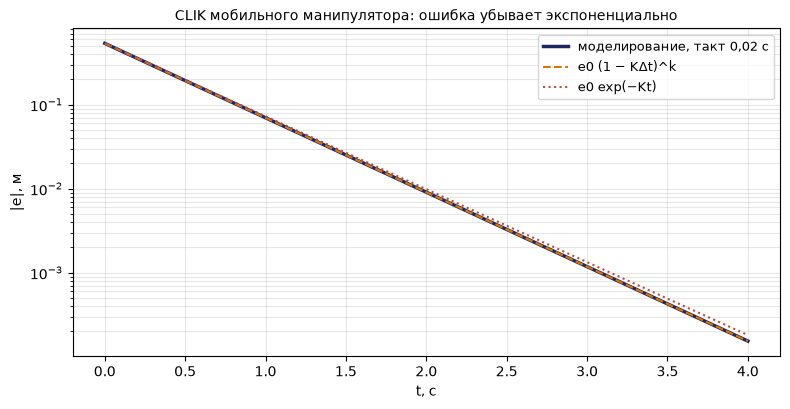

In [9]:
def fk_e(x):
    bx, by, th, q1, q2 = x; p = arm([q1, q2])[0]; R = wheeled.rotz(th)[:2, :2]
    pe = np.array([bx, by]) + R.dot(p); return np.array([pe[0], pe[1], th + q1 + q2])

x = np.array([0.0, 0.0, 0.0, 0.0, np.pi / 2]); target = fk_e(x) + np.array([0.5, 0.2, 0.0])
dt, K = 0.02, 2.0; t_, e_ = [0.0], [np.linalg.norm(target - fk_e(x))]
for k in range(200):
    e = target - fk_e(x)
    z = np.linalg.pinv(wheeled.rotz(x[2]).dot(J_e(x[3:]))).dot(K * e)   # J_e в мировых осях: R_z(θ) J_e
    x[:3] += wheeled.rotz(x[2]).dot(z[:3]) * dt; x[3:] += z[3:] * dt
    t_.append((k + 1) * dt); e_.append(np.linalg.norm(target - fk_e(x)))
t_, e_ = np.array(t_), np.array(e_)
for T in (1, 2, 4):
    k = int(round(T / dt))
    print('t = %d с (%3d тактов): |e| = %.2e м;  e0·0,96^k = %.2e;  e0·exp(−Kt) = %.2e' % (T, k, e_[k], e_[0] * (1 - K * dt) ** k, e_[0] * np.exp(-K * T)))
print('e0 = %.4f м; отношение соседних ошибок в середине пути: %.5f (1 − KΔt = %.2f)' % (e_[0], e_[101] / e_[100], 1 - K * dt))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.semilogy(t_, e_, color=NAVY, lw=2.5, label='моделирование, такт 0,02 с')
ax.semilogy(t_, e_[0] * (1 - K * dt) ** (t_ / dt), color=AMB, ls='--', lw=1.5, label='e0 (1 − KΔt)^k')
ax.semilogy(t_, e_[0] * np.exp(-K * t_), color=RED, ls=':', lw=1.5, label='e0 exp(−Kt)')
ax.grid(alpha=.3, which='both'); ax.legend(fontsize=9); ax.set_xlabel('t, с'); ax.set_ylabel('|e|, м'); ax.set_title('CLIK мобильного манипулятора: ошибка убывает экспоненциально', fontsize=10)
plt.tight_layout(); plt.show()

## 9. Рука на дифференциальной тележке (§ 8.10, шаг 6)

Та же рука на дифференциальной тележке: переменные $(v,\omega,\dot q_1,\dot q_2)$, боковой скорости у тележки нет. Столбцы $\omega$ и $\dot q_1$ совпадают всегда — оба описывают поворот вокруг вертикали через точку $P$. Определитель столбцов $(v,\dot q_1,\dot q_2)$ равен $a_1c_1$, поэтому ранг падает до двух, когда локоть оказывается на оси колёс, $q_1=\pm90^{\circ}$.

Какое направление теряется? При постоянной ориентации схвата $\omega+\dot q_1+\dot q_2=0$, и скорость схвата равна $v\hat{\mathbf x}+\dot q_2\,\hat{\mathbf z}\times(\mathbf r_{P,\mathrm{e}}-\mathbf r_{P,\mathrm{elbow}})-\dot q_2\,\hat{\mathbf z}\times\mathbf r_{Pe}=v\hat{\mathbf x}-\dot q_2\,\hat{\mathbf z}\times\mathbf r_{P,\mathrm{elbow}}$. При $q_1=90^{\circ}$ вектор $\mathbf r_{P,\mathrm{elbow}}=(0;\ a_1)$, и $\hat{\mathbf z}\times\mathbf r_{P,\mathrm{elbow}}$ направлен по $\hat{\mathbf x}$: схват может двигаться только вдоль курса тележки и **не может — вдоль первого звена руки, то есть вбок от курса**. Левый вектор ядра $J$ это подтверждает: его компонента по $\dot y_e$ — главная.

In [10]:
def J_dd(q):
    r_Pe, Jv = arm(q)
    return np.array([[1.0, -r_Pe[1], Jv[0, 0], Jv[0, 1]], [0.0, r_Pe[0], Jv[1, 0], Jv[1, 1]], [0.0, 1.0, 1.0, 1.0]])

Jd = J_dd(rad([25.0, 60.0])); print('столбцы ω и q̇1 совпадают:', np.allclose(Jd[:, 1], Jd[:, 2]))
for q1d in (0, 30, 60, 90):
    Jd = J_dd(rad([q1d, 70.0])); print('q1 = %2d°: det(v, q̇1, q̇2) = %.5f, a1 cos q1 = %.5f' % (q1d, np.linalg.det(Jd[:, [0, 2, 3]]), a1 * np.cos(rad(q1d))))
for q2d in (30, 70, 120):
    Jd = J_dd(rad([90.0, q2d])); rd = analyze(Jd, 'q = (90°; %d°)' % q2d)
    print('   левый вектор ядра (ẋe, ẏe, φ̇e):', rd['u_min'].round(3))
    for tgt in ([0.1, 0, 0], [0, 0.1, 0]):
        zz = np.linalg.pinv(Jd).dot(tgt); print('   цель %s: невязка %.4f м/с' % (tgt, np.linalg.norm(Jd.dot(zz) - tgt)))
analyze(J_dd(rad([0.0, 0.0])), '\nрука вдоль курса, q = (0; 0)')
print('решение для схвата (−0,1; 0; 0):', np.linalg.pinv(J_dd(rad([0.0, 0.0]))).dot([-0.1, 0, 0]).round(4), '— отъезжает тележка')

столбцы ω и q̇1 совпадают: True
q1 =  0°: det(v, q̇1, q̇2) = 0.30000, a1 cos q1 = 0.30000
q1 = 30°: det(v, q̇1, q̇2) = 0.25981, a1 cos q1 = 0.25981
q1 = 60°: det(v, q̇1, q̇2) = 0.15000, a1 cos q1 = 0.15000
q1 = 90°: det(v, q̇1, q̇2) = 0.00000, a1 cos q1 = 0.00000
q = (90°; 30°)                     3x4  ранг 2  σ = [1.9838 0.909  0.    ]  κ = inf  ядро: 2
   левый вектор ядра (ẋe, ẏe, φ̇e): [-0.     0.989  0.148]
   цель [0.1, 0, 0]: невязка 0.0000 м/с
   цель [0, 0.1, 0]: невязка 0.0989 м/с
q = (90°; 70°)                     3x4  ранг 2  σ = [1.9044 0.9729 0.    ]  κ = inf  ядро: 2
   левый вектор ядра (ẋe, ẏe, φ̇e): [0.    0.962 0.271]
   цель [0.1, 0, 0]: невязка 0.0000 м/с
   цель [0, 0.1, 0]: невязка 0.0962 м/с
q = (90°; 120°)                    3x4  ранг 2  σ = [1.7927 1.0278 0.    ]  κ = inf  ядро: 2
   левый вектор ядра (ẋe, ẏe, φ̇e): [-0.     0.968  0.251]
   цель [0.1, 0, 0]: невязка 0.0000 м/с
   цель [0, 0.1, 0]: невязка 0.0968 м/с

рука вдоль курса, q = (0; 0)      3x4  ран

## 10. Интерактив «сломай и посмотри» (§ 8.3, § 8.4)

Ползунок $q_2$ двухзвенника с единичными звеньями ($q_1=30^{\circ}$): эллипс скоростей (синий) и эллипс сил (красный) в масштабе $0{,}4$, наименьшее сингулярное число, число обусловленности и пороги модуля MoveIt Servo $17$ и $30$. Подведите локоть к $0^{\circ}$: эллипс скоростей сплющивается в отрезок поперёк руки, эллипс сил вытягивается вдоль руки, а $\kappa(J)$ уходит за порог остановки при $q_2\approx9{,}5^{\circ}$.

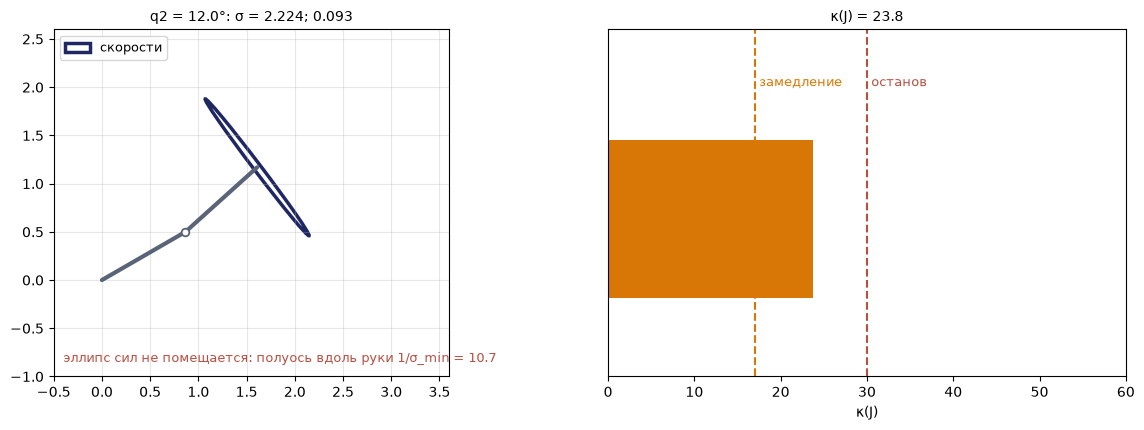

interactive(children=(FloatSlider(value=60.0, description='q2, °', max=175.0, min=0.5, step=0.5), Output()), _…

In [11]:
def show(q2=60.0):
    q = rad([30.0, q2]); J = J2(q); U, S, Vt = np.linalg.svd(J); p = trajlib.fk2(q)
    k = S[0] / S[1] if S[1] > 1e-9 else np.inf
    fig, axs = plt.subplots(1, 2, figsize=(12.5, 4.4), gridspec_kw=dict(width_ratios=[1.3, 1]))
    ax = axs[0]; trajlib.draw_arm(ax, q, color=GREY); ang = deg(np.arctan2(U[1, 0], U[0, 0]))
    ax.add_patch(Ellipse(p, 0.8 * S[0], 0.8 * S[1], angle=ang, fc='none', ec=NAVY, lw=2.5, label='скорости'))
    if S[1] > 0.2:
        ax.add_patch(Ellipse(p, 0.8 / S[0], 0.8 / S[1], angle=ang, fc='none', ec=RED, lw=2, label='силы'))
    else:
        ax.text(-0.4, -0.85, 'эллипс сил не помещается: полуось вдоль руки 1/σ_min = %.1f' % (1 / max(S[1], 1e-9)), color=RED, fontsize=9)
    ax.set_aspect('equal'); ax.set_xlim(-0.5, 3.6); ax.set_ylim(-1.0, 2.6); ax.grid(alpha=.3); ax.legend(fontsize=9, loc='upper left')
    ax.set_title('q2 = %.1f°: σ = %.3f; %.3f' % (q2, S[0], S[1]), fontsize=10)
    ax = axs[1]; col = GREEN if k < 17 else (AMB if k < 30 else RED)
    ax.barh([0], [min(k, 60)], height=0.5, color=col); ax.axvline(17, color=AMB, ls='--'); ax.axvline(30, color=RED, ls='--')
    ax.text(17.5, 0.42, 'замедление', color=AMB, fontsize=9); ax.text(30.5, 0.42, 'останов', color=RED, fontsize=9); ax.set_ylim(-0.5, 0.6)
    ax.set_xlim(0, 60); ax.set_yticks([]); ax.set_xlabel('κ(J)'); ax.set_title('κ(J) = %s' % ('%.1f' % k if np.isfinite(k) else 'inf'), fontsize=10)
    plt.tight_layout(); plt.show()

show(12.0)   # статичный кадр для сохранённого ноутбука: q2 = 12° — между порогами замедления и останова
if interact is not None:
    interact(show, q2=FloatSlider(value=60.0, min=0.5, max=175.0, step=0.5, description='q2, °'))
else:
    show(60.0)